<style>
.jp-CodeCell, .code_cell {border-left: 5px solid #2e7d32 !important;}
.jp-InputArea, div.input_area {background: #f1f8e9 !important;}
.jp-OutputArea, div.output_area {background: #fbfff8 !important;}
.note {background:#eef6ff; border-left:5px solid #1976d2; padding:10px 14px; margin:12px 0;}
.activity {background:#fff8e1; border-left:5px solid #f9a825; padding:10px 14px; margin:12px 0;}
.important {background:#ffebee; border-left:5px solid #c62828; padding:10px 14px; margin:12px 0;}
</style>

# SBI811 — Lecture 8
## Applying Python and Computational Thinking to Biological Problems

This lecture brings together familiar Python ideas—variables, strings, lists, loops, conditions and functions—and applies them to three scientific problems:

1. calculating GC percentage;
2. comparing short DNA sequences; and
3. studying enzyme kinetics.

Dynamic programming is introduced through a small table completed by hand. The purpose is to understand the reasoning, not to write a difficult alignment program.

## Learning outcomes

By the end of the lecture, a student should be able to:

1. translate a scientific question into input, processing and output;
2. calculate GC percentage using a short Python program;
3. calculate Hamming distance by hand and with a simple loop;
4. explain why Hamming distance requires sequences of equal length;
5. explain dynamic programming as storing solutions to smaller problems;
6. complete a small edit-distance table by hand;
7. calculate reaction velocities using the Michaelis–Menten equation;
8. construct and interpret Michaelis–Menten and Lineweaver–Burk plots; and
9. connect biological meaning to computational results.

## Lecture map

| Approximate time | Topic |
|---:|---|
| 0–20 min | From a scientific question to an algorithm |
| 20–45 min | Hamming distance |
| 45–80 min | Dynamic programming completed by hand |
| 80–90 min | Break or recap |
| 90–150 min | Michaelis–Menten enzyme kinetics |
| 150–180 min | Exercises and discussion |

No FASTA-reading code is included because file parsing was covered in an earlier lecture.

# Part 1 — From a scientific question to an algorithm

An **algorithm** is an ordered set of clear steps for solving a problem.

Before writing Python, identify three things:

| Part | Question |
|---|---|
| Input | What information is supplied? |
| Processing | What operations must be performed? |
| Output | What answer should be produced? |

This structure prevents us from writing code before understanding the scientific problem.

## Example: GC percentage

**Scientific question:** What percentage of a DNA sequence consists of guanine and cytosine?

### Input

A DNA sequence, for example:

```text
ATGCGTAA
```

### Processing

1. convert the sequence to uppercase;
2. remove spaces or line breaks at its ends;
3. count `G`;
4. count `C`;
5. add the two counts;
6. divide by the sequence length; and
7. multiply by 100.

### Output

The GC percentage.

The formula is:

$$
\text{GC percentage}=\frac{\text{number of G bases}+\text{number of C bases}}{\text{sequence length}}\times100
$$

## A short Python solution

The following program uses only string methods, `len()` and arithmetic already introduced in earlier lectures.

In [ ]:
dna = "ATGCGTAA"

clean_dna = dna.strip().upper()

g_count = clean_dna.count("G")
c_count = clean_dna.count("C")
sequence_length = len(clean_dna)

gc_count = g_count + c_count
gc_percentage = gc_count / sequence_length * 100

print("DNA sequence:", clean_dna)
print("Sequence length:", sequence_length)
print("Number of G bases:", g_count)
print("Number of C bases:", c_count)
print("GC percentage:", gc_percentage)


### Reading the program

- `strip()` removes unwanted spaces and line breaks from the two ends.
- `upper()` converts lowercase letters to uppercase.
- `count("G")` counts G bases.
- `count("C")` counts C bases.
- `len(clean_dna)` gives the number of characters.
- The calculation follows the biological formula directly.

For `ATGCGTAA`, there are two G bases and one C base. Therefore:

$$
\frac{2+1}{8}\times100=37.5\%
$$

The hand calculation and Python result should agree.

# Part 2 — Comparing equal-length sequences

## 2.1 Hamming distance

The **Hamming distance** is the number of positions at which two equal-length sequences differ.

Consider:

```text
Sequence 1: A T G C C G T A
Sequence 2: A T G T C G A A
                    ↑     ↑
Position:   1 2 3 4 5 6 7 8
```

The sequences differ at positions 4 and 7. Their Hamming distance is therefore **2**.

<div class="important">
Hamming distance can be used only when the two sequences have the same length.
</div>

## 2.2 Hamming distance by hand

Use the following table:

| Position | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| Sequence 1 | A | T | G | C | C | G | T | A |
| Sequence 2 | A | T | G | T | C | G | A | A |
| Same or different? | Same | Same | Same | Different | Same | Same | Different | Same |
| Add to distance | 0 | 0 | 0 | 1 | 0 | 0 | 1 | 0 |

Adding the last row gives:

$$0+0+0+1+0+0+1+0=2$$

### Pseudocode

```text
Set distance to zero

For every pair of bases at the same position:
    If the two bases are different:
        Add one to distance

Display distance
```

## 2.3 A simple Python loop

`zip()` places corresponding characters into pairs:

```text
(A, A), (T, T), (G, G), (C, T), ...
```

The loop then checks one pair at a time.

In [ ]:
sequence_1 = "ATGCCGTA"
sequence_2 = "ATGTCGAA"

hamming_distance = 0

for base_1, base_2 in zip(sequence_1, sequence_2):
    if base_1 != base_2:
        hamming_distance = hamming_distance + 1

print("Hamming distance:", hamming_distance)


### Following the variables

| Loop step | `base_1` | `base_2` | Are they different? | New distance |
|---:|---|---|---|---:|
| 1 | A | A | No | 0 |
| 2 | T | T | No | 0 |
| 3 | G | G | No | 0 |
| 4 | C | T | Yes | 1 |
| 5 | C | C | No | 1 |
| 6 | G | G | No | 1 |
| 7 | T | A | Yes | 2 |
| 8 | A | A | No | 2 |

`!=` means **not equal to**. The distance increases only when the bases differ.

## 2.4 Check sequence lengths first

Because `zip()` stops when the shorter sequence ends, using it without checking lengths could give a misleading answer.

The following code checks the requirement before starting the loop.

In [ ]:
sequence_1 = "ACTG"
sequence_2 = "ACT"

if len(sequence_1) != len(sequence_2):
    print("Hamming distance cannot be calculated.")
    print("The sequences have different lengths.")
else:
    distance = 0

    for base_1, base_2 in zip(sequence_1, sequence_2):
        if base_1 != base_2:
            distance = distance + 1

    print("Hamming distance:", distance)


The program uses an ordinary `if...else` statement:

- if the lengths differ, it prints an explanation;
- otherwise, it performs the comparison.

This is preferable to returning a complicated value that beginners may not understand.

# Part 3 — Why dynamic programming is needed

Consider:

```text
Sequence 1: A T G C T
Sequence 2: A T C T
```

The sequences have different lengths, so Hamming distance is unsuitable.

However, deleting `G` from the first sequence produces the second sequence:

```text
ATGCT  →  ATCT
```

Only one edit is required.

Possible edit operations are:

| Operation | Meaning | Example |
|---|---|---|
| Substitution | Replace one character | A → G |
| Insertion | Add one character | AT → AGT |
| Deletion | Remove one character | AGT → AT |

The **edit distance** is the smallest number of these operations needed to change one sequence into another.

## 3.1 What is dynamic programming?

Dynamic programming solves a larger problem by:

1. dividing it into smaller problems;
2. solving each smaller problem once;
3. storing each answer in a table; and
4. using stored answers to solve larger parts.

For sequence comparison, each table cell answers this question:

> What is the edit distance between the sequence prefixes that end at this cell?

A **prefix** is the beginning part of a sequence.

For `AT`, the prefixes are:

```text
empty sequence, A, AT
```

<div class="note">
We will complete a very small dynamic-programming table by hand. We will not write the Python implementation of edit distance in this lecture.
</div>

## 3.2 A small hand-worked example

Compare:

```text
Sequence across the columns: AT
Sequence down the rows:      AG
```

We expect one substitution: replace `T` with `G`.

Begin with an empty table:

|  | empty | A | T |
|---|---:|---:|---:|
| **empty** |  |  |  |
| **A** |  |  |  |
| **G** |  |  |  |

The word **empty** represents a sequence containing no characters.

## 3.3 Fill the first row and first column

Changing an empty sequence into `A` requires one insertion. Changing it into `AT` requires two insertions.

Similarly, changing `A` into an empty sequence requires one deletion, while changing `AG` into an empty sequence requires two deletions.

|  | empty | A | T |
|---|---:|---:|---:|
| **empty** | 0 | 1 | 2 |
| **A** | 1 |  |  |
| **G** | 2 |  |  |

The values increase from zero because longer prefixes require more insertions or deletions.

## 3.4 The three neighbours used by an internal cell

Every empty internal cell looks at three already completed neighbours:

| Neighbour | Movement | Biological meaning |
|---|---|---|
| Above | move down | deletion |
| Left | move right | insertion |
| Diagonal | move diagonally | match or substitution |

For deletion and insertion, add 1.

For the diagonal movement:

- add 0 when the two letters match;
- add 1 when the two letters differ.

The cell receives the smallest of the three possible totals.

## 3.5 Fill the first internal cell: A compared with A

The letters match.

The three choices are:

| Choice | Calculation | Result |
|---|---:|---:|
| From above | 1 + 1 | 2 |
| From left | 1 + 1 | 2 |
| From diagonal | 0 + 0 because A matches A | 0 |

Choose the smallest result, which is 0.

|  | empty | A | T |
|---|---:|---:|---:|
| **empty** | 0 | 1 | 2 |
| **A** | 1 | **0** |  |
| **G** | 2 |  |  |

No edit is needed to change `A` into `A`.

## 3.6 Complete the remaining cells

### Cell comparing row A with column T

The smallest choice is 1. One insertion or deletion is needed when comparing prefixes `A` and `AT`.

### Cell comparing row G with column A

The smallest choice is 1. The prefixes `AG` and `A` differ by one added or removed character.

### Cell comparing row G with column T

The letters G and T differ. The diagonal choice is:

$$0+1=1$$

The completed table is:

|  | empty | A | T |
|---|---:|---:|---:|
| **empty** | 0 | 1 | 2 |
| **A** | 1 | 0 | 1 |
| **G** | 2 | 1 | **1** |

The final answer is found in the bottom-right cell.

Therefore:

$$\text{edit distance}(AT,AG)=1$$

This agrees with the simple biological explanation: substitute `T` with `G`.

## 3.7 A second example: one deletion

Compare `AT` with `A`:

|  | empty | A | T |
|---|---:|---:|---:|
| **empty** | 0 | 1 | 2 |
| **A** | 1 | 0 | **1** |

The bottom-right value is 1.

This represents one deletion:

```text
AT → A
```

### What students should understand

- The table stores answers to smaller prefix comparisons.
- The first row and column describe comparisons with an empty sequence.
- Each internal cell uses the cells above, left and diagonally above-left.
- The bottom-right cell contains the edit distance for the complete sequences.
- The table can compare sequences of different lengths.

Students are not expected to implement this table in Python in this lecture.

## 3.8 Hamming distance and edit distance compared

| Property | Hamming distance | Edit distance |
|---|---|---|
| Required sequence lengths | Must be equal | May be equal or different |
| Differences considered | Position-by-position mismatches | Insertions, deletions and substitutions |
| Beginner implementation | Simple loop | Dynamic-programming table |
| Treatment in this lecture | Hand calculation and Python | Hand calculation only |

Hamming distance is simpler but more limited. Edit distance is more flexible, but its dynamic-programming implementation is postponed until students have more programming experience.

# Part 4 — Enzyme kinetics

## 4.1 The biological question

An enzyme converts substrate into product. The initial reaction velocity is measured at several substrate concentrations.

Typical questions are:

- Does velocity increase as substrate concentration increases?
- Does the increase continue at the same rate?
- What is the estimated maximum velocity, $V_{max}$?
- What substrate concentration gives half of $V_{max}$?

The small dataset below is included directly in the notebook, so no external file is required.

## 4.2 Store the experimental measurements in a DataFrame

The measurements belong together, so they are stored in one table called `enzyme_data`.

| substrate_concentration | reaction_velocity |
|---:|---:|
| 0.5 | 10.0 |
| 1.0 | 16.7 |
| 2.0 | 25.0 |
| 4.0 | 33.3 |
| 8.0 | 40.0 |

Each **row** represents one experiment. For example, the first row says that a substrate concentration of 0.5 mM produced a reaction velocity of 10.0 µmol/min.

The two columns can now be used directly in calculations and graphs. We do not need to create separate lists.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Create one table containing all experimental measurements.
enzyme_data = pd.DataFrame({
    "substrate_concentration": [0.5, 1.0, 2.0, 4.0, 8.0],
    "reaction_velocity": [10.0, 16.7, 25.0, 33.3, 40.0]
})

# Display the complete table.
enzyme_data


,substrate_concentration,reaction_velocity
0,0.5,10.0
1,1.0,16.7
2,2.0,25.0
3,4.0,33.3
4,8.0,40.0


## 4.3 Plot the observed measurements

A scatter plot displays every measured pair. Connecting the points helps the eye follow the pattern, but the connecting line is not yet a fitted biochemical model.

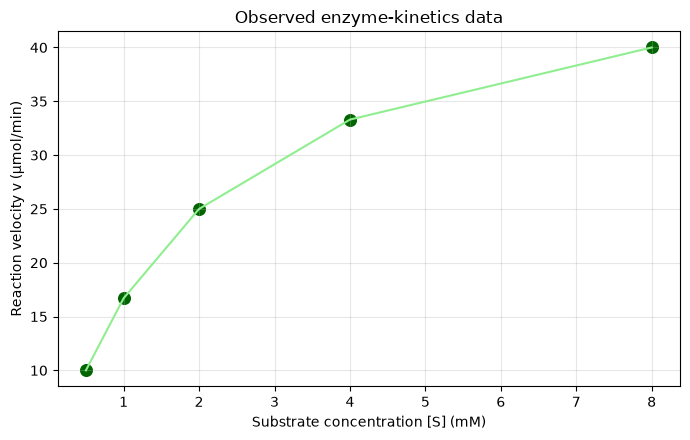

In [2]:
# Draw the observed measurements directly from the DataFrame.
plt.figure(figsize=(7, 4.5))

plt.scatter(
    enzyme_data["substrate_concentration"],
    enzyme_data["reaction_velocity"],
    color="darkgreen",
    s=70
)

plt.plot(
    enzyme_data["substrate_concentration"],
    enzyme_data["reaction_velocity"],
    color="lightgreen"
)

plt.xlabel("Substrate concentration [S] (mM)")
plt.ylabel("Reaction velocity v (µmol/min)")
plt.title("Observed enzyme-kinetics data")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Interpreting the graph

- Velocity increases when substrate concentration increases.
- The increases become smaller at high substrate concentrations.
- The curve appears to approach a plateau.

This pattern is consistent with enzyme saturation.

## 4.4 The Michaelis–Menten equation

The Michaelis–Menten equation is:

$$
v=\frac{V_{max}[S]}{K_m+[S]}
$$

| Symbol | Meaning |
|---|---|
| $v$ | predicted reaction velocity |
| $[S]$ | substrate concentration |
| $V_{max}$ | maximum velocity approached at high substrate concentration |
| $K_m$ | substrate concentration at which velocity equals half of $V_{max}$ |

When $[S]=K_m$:

$$
v=\frac{V_{max}}{2}
$$

## 4.5 A simple Michaelis–Menten function

The function translates the equation directly into Python.

In [3]:
def michaelis_menten(substrate_concentration, vmax, km):
    numerator = vmax * substrate_concentration
    denominator = km + substrate_concentration
    predicted_velocity = numerator / denominator

    return predicted_velocity


The calculation is separated into three named steps:

1. calculate the numerator;
2. calculate the denominator;
3. divide the numerator by the denominator.

This is longer than writing the whole equation on one line, but each part is easier to inspect.

In [4]:
example_velocity = michaelis_menten(
    substrate_concentration=2.0,
    vmax=50.0,
    km=2.0
)

print("Predicted velocity:", example_velocity, "µmol/min")


Predicted velocity: 25.0 µmol/min


Here, substrate concentration equals $K_m$. The answer should therefore be half of $V_{max}$:

$$
\frac{50}{2}=25\text{ µmol/min}
$$

The expected answer gives us a simple way to check the function.

## 4.6 The Lineweaver–Burk transformation

Taking reciprocals of the Michaelis–Menten equation gives:

$$
\frac{1}{v}=\frac{K_m}{V_{max}}\frac{1}{[S]}+\frac{1}{V_{max}}
$$

This has the straight-line form:

$$y=mx+c$$

| Straight-line quantity | Enzyme-kinetics quantity |
|---|---|
| $y$ | $1/v$ |
| $x$ | $1/[S]$ |
| slope $m$ | $K_m/V_{max}$ |
| y-intercept $c$ | $1/V_{max}$ |

The reciprocal transformation allows a straight line to be fitted.

## 4.7 Add the reciprocal columns

Reciprocal means one divided by a value. We add two new columns to the same DataFrame:

- `inverse_substrate` contains $1/[S]$;
- `inverse_velocity` contains $1/v$.

The expression `enzyme_data["substrate_concentration"]` selects the complete substrate column. Pandas performs the division for every row and stores the answers in the new column.

A zero concentration or zero velocity would cause division by zero. The supplied dataset contains no zeros.

In [5]:
# Add the two reciprocal columns to the existing table.
enzyme_data["inverse_substrate"] = 1 / enzyme_data["substrate_concentration"]
enzyme_data["inverse_velocity"] = 1 / enzyme_data["reaction_velocity"]

# Display the table after adding the new columns.
enzyme_data.round(3)


,substrate_concentration,reaction_velocity,inverse_substrate,inverse_velocity
0,0.5,10.0,2.000,0.100
1,1.0,16.7,1.000,0.060
2,2.0,25.0,0.500,0.040
3,4.0,33.3,0.250,0.030
4,8.0,40.0,0.125,0.025


## 4.8 Fit the straight line

NumPy contains a function called `polyfit()` that can fit a straight line.

The final argument is `1` because a straight line is a polynomial of degree 1.

The function returns:

1. the slope; and
2. the y-intercept.

We use the library function here because fitting experimental data is a realistic computer task. Students are not expected to program the fitting algorithm themselves.

## 4.9 Recover $V_{max}$ and $K_m$

From the y-intercept:

$$
V_{max}=\frac{1}{\text{intercept}}
$$

From the slope:

$$
K_m=\text{slope}\times V_{max}
$$

The complete analysis is kept in one code cell below. The comments identify each stage without separating the connected calculations into many small code cells.

The estimates should be interpreted with their units:

- $V_{max}$ has velocity units, µmol/min;
- $K_m$ has concentration units, mM.

A number without its unit is an incomplete scientific result.

## 4.10 Fit and draw the Lineweaver–Burk plot

The observed reciprocal values are plotted as points. A fitted y-value is calculated for each observed x-value using:

$$y=mx+c$$

This avoids introducing a longer and less familiar plotting procedure.

Estimated Vmax: 50.01 µmol/min
Estimated Km: 2.0 mM


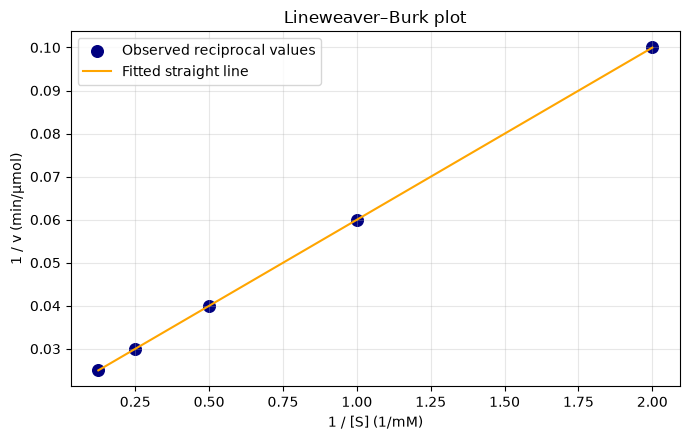

In [6]:
import numpy as np

# 1. Fit a straight line to the two reciprocal columns.
slope, intercept = np.polyfit(
    enzyme_data["inverse_substrate"],
    enzyme_data["inverse_velocity"],
    1
)

# 2. Recover Vmax and Km from the fitted line.
estimated_vmax = 1 / intercept
estimated_km = slope * estimated_vmax

print("Estimated Vmax:", round(estimated_vmax, 2), "µmol/min")
print("Estimated Km:", round(estimated_km, 2), "mM")

# 3. Calculate the fitted y-value for every observed x-value.
enzyme_data["fitted_inverse_velocity"] = (
    slope * enzyme_data["inverse_substrate"] + intercept
)

# 4. Draw the observed reciprocal points and fitted straight line.
plt.figure(figsize=(7, 4.5))

plt.scatter(
    enzyme_data["inverse_substrate"],
    enzyme_data["inverse_velocity"],
    color="navy",
    s=70,
    label="Observed reciprocal values"
)

plt.plot(
    enzyme_data["inverse_substrate"],
    enzyme_data["fitted_inverse_velocity"],
    color="orange",
    label="Fitted straight line"
)

plt.xlabel("1 / [S] (1/mM)")
plt.ylabel("1 / v (min/µmol)")
plt.title("Lineweaver–Burk plot")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 4.11 Plot the fitted Michaelis–Menten curve

The following table supplies substrate concentrations from 0 to 10 mM. The Michaelis–Menten function is applied directly to its substrate column. Pandas stores all predicted velocities in a second column.

The data preparation, prediction and graph are kept together in one code cell.

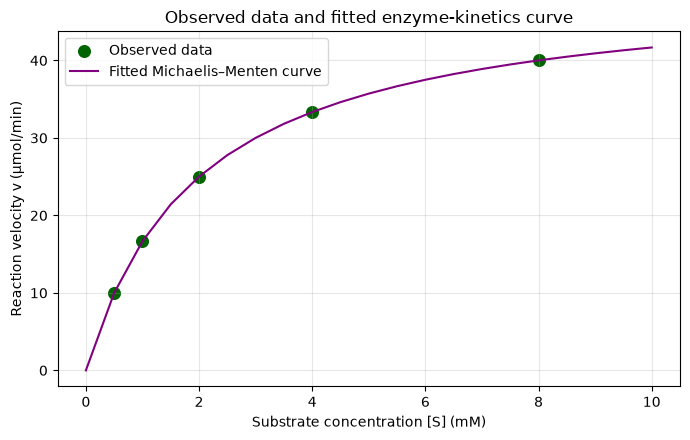

In [7]:
# 1. Create a DataFrame containing concentrations for the smooth curve.
curve_data = pd.DataFrame({
    "substrate_concentration": [
        0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0,
        3.5, 4.0, 4.5, 5.0, 5.5, 6.0, 6.5,
        7.0, 7.5, 8.0, 8.5, 9.0, 9.5, 10.0
    ]
})

# 2. Apply the equation to the complete concentration column.
curve_data["predicted_velocity"] = michaelis_menten(
    curve_data["substrate_concentration"],
    estimated_vmax,
    estimated_km
)

# 3. Plot the observed measurements and the predicted curve.
plt.figure(figsize=(7, 4.5))

plt.scatter(
    enzyme_data["substrate_concentration"],
    enzyme_data["reaction_velocity"],
    color="darkgreen",
    s=70,
    label="Observed data"
)

plt.plot(
    curve_data["substrate_concentration"],
    curve_data["predicted_velocity"],
    color="purple",
    label="Fitted Michaelis–Menten curve"
)

plt.xlabel("Substrate concentration [S] (mM)")
plt.ylabel("Reaction velocity v (µmol/min)")
plt.title("Observed data and fitted enzyme-kinetics curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 4.12 Scientific interpretation

A careful interpretation separates observations from model estimates:

- The observed velocity increases with substrate concentration.
- The increase becomes smaller at high substrate concentration.
- The fitted curve approaches the estimated $V_{max}$.
- The estimated $K_m$ is the concentration at which predicted velocity is half of $V_{max}$.

### Limitation

The Lineweaver–Burk transformation gives strong influence to measurements at small substrate concentrations because their reciprocals are large. Modern analyses often fit the Michaelis–Menten curve directly, but the Lineweaver–Burk plot remains useful for teaching the relationship between the equation and a straight line.

# Part 5 — Bringing the applications together

| Stage | Sequence comparison | Enzyme kinetics |
|---|---|---|
| Input | DNA sequences | substrate concentrations and velocities |
| Processing | compare characters or fill a table | calculate predictions or reciprocals |
| Output | sequence distance | parameter estimates and plots |
| Biological interpretation | how different are the sequences? | how does velocity respond to substrate? |

Both applications require the same general habits:

1. understand the scientific question;
2. identify input, processing and output;
3. select an appropriate method;
4. test the method with a simple example; and
5. interpret the result scientifically.

# Part 6 — Guided exercises

## Exercise 1: GC percentage

For the sequence `AATGCCGGTA`:

1. calculate GC percentage by hand;
2. modify the GC program to check your answer; and
3. state the sequence length, G count and C count.

## Exercise 2: Hamming distance

Compare:

```text
Sequence 1: A C T G A A
Sequence 2: A T T G C A
```

1. mark every mismatching position;
2. calculate Hamming distance by hand;
3. modify the simple loop to check the answer; and
4. trace the value of `hamming_distance` after every loop iteration.

## Exercise 3: choosing a method

For each pair, state whether Hamming distance can be used and explain why:

1. `ACTG` and `ATTG`;
2. `ACTG` and `ATG`;
3. `ACTG` and `ACTG`.

## Exercise 4: dynamic programming by hand

Complete the edit-distance table for `AC` and `AT`.

|  | empty | A | C |
|---|---:|---:|---:|
| **empty** | 0 | 1 | 2 |
| **A** | 1 |  |  |
| **T** | 2 |  |  |

For each internal cell:

1. write the value from above plus 1;
2. write the value from the left plus 1;
3. write the diagonal value plus 0 for a match or plus 1 for a mismatch;
4. enter the smallest result in the cell; and
5. explain the bottom-right answer using one edit operation.

Do this exercise on paper. No Python code is required.

## Exercise 5: enzyme prediction

Use the `michaelis_menten()` function and the estimated parameters to:

1. predict velocity at 3 mM substrate;
2. predict velocity when substrate concentration equals the estimated $K_m$;
3. calculate estimated $V_{max}/2$; and
4. explain why answers 2 and 3 should be approximately equal.

## Exercise 6: interpreting a graph

Using the fitted Michaelis–Menten graph:

1. describe the relationship at low substrate concentrations;
2. describe the relationship at high substrate concentrations;
3. identify the meaning of the plateau; and
4. explain why the fitted curve does not pass through every measured point in a real experiment.

# Part 7 — Common mistakes and debugging questions

| Mistake | Likely result | Question to ask |
|---|---|---|
| comparing unequal-length sequences with Hamming distance | incomplete or misleading comparison | Did I check both lengths? |
| using `=` instead of `!=` | invalid condition or wrong logic | Am I testing whether bases differ? |
| increasing distance for matching bases | distance becomes too large | Is the addition inside the mismatch condition? |
| reading the wrong edit-distance cell | incorrect final answer | Did I use the bottom-right cell? |
| forgetting reciprocal units | incomplete scientific result | What happened to the units after inversion? |
| dividing by zero when calculating reciprocals | error | Does the dataset contain zero? |
| interpreting a connected line as a fitted model | unsupported conclusion | Is this line observed data or a model? |
| reporting $V_{max}$ or $K_m$ without units | incomplete interpretation | What are the original velocity and concentration units? |

# Review questions

1. What is an algorithm?
2. Why is pseudocode useful before writing Python?
3. What does Hamming distance count?
4. Why must Hamming-distance sequences have equal length?
5. What problem can edit distance solve that Hamming distance cannot?
6. What does dynamic programming store?
7. Why are the first row and column of an edit-distance table filled with 0, 1, 2 and so on?
8. Where is the final edit distance found in the table?
9. What does $V_{max}$ represent?
10. What does $K_m$ represent?
11. Why is velocity equal to half of $V_{max}$ when substrate concentration equals $K_m$?
12. What do the slope and intercept represent in a Lineweaver–Burk plot?

# Key terms

| Term | Meaning |
|---|---|
| algorithm | ordered and unambiguous steps for solving a problem |
| pseudocode | program logic written in structured ordinary language |
| Hamming distance | number of mismatching positions in equal-length sequences |
| edit distance | minimum number of insertions, deletions and substitutions |
| dynamic programming | solving smaller problems once and storing their answers |
| prefix | beginning portion of a sequence |
| substrate | molecule acted upon by an enzyme |
| reaction velocity | rate at which product is formed |
| $V_{max}$ | maximum velocity approached at high substrate concentration |
| $K_m$ | substrate concentration producing half of $V_{max}$ |
| reciprocal | one divided by a value |
| Lineweaver–Burk plot | straight-line plot of $1/v$ against $1/[S]$ |

# Lecture summary

In this lecture:

- GC percentage demonstrated how a biological formula becomes a short program.
- Hamming distance was calculated by hand and with a simple loop.
- Dynamic programming was introduced using a small edit-distance table completed by hand.
- No edit-distance Python implementation was required.
- The Michaelis–Menten equation was converted into a short function.
- Experimental enzyme data were plotted and transformed.
- A Lineweaver–Burk line was used to estimate $V_{max}$ and $K_m$.

The central lesson is not that every biological algorithm must be programmed immediately. First understand the problem and its logic. Code should be introduced only when it makes the scientific work clearer or more practical.